# <font color='#E8800A'>Import and explore the data</font> <a class="anchor" id="Import"></a>

#### Data dictionary: `train.csv` joined with `clientes.csv` on `customer_id`

Each row of `train.csv` is one purchase. `clientes.csv` has one row per customer, so its columns repeat the same value on every purchase of that customer.

The money columns add up as: `Total Bruto` − `Total Desc_ Linha` − `Total Desc_ Global` = `Total Liquido`, and `Total Liquido` + `Total Imp_` (+ `Total Portes`) = `Total a Pagar`.

Counts are stored as float only because the column has missing values (NaN is a float).

| column | source | what it holds | type/role |
|---|---|---|---|
| `ID` | train | unique id of the purchase | index, never a feature |
| `Total a Pagar` | train | total the customer pays for this purchase (net + tax + shipping) | float, money |
| `Total Bruto` | train | gross value of the items, before discounts and tax | float, money |
| `Total Liquido` | train | net value, after discounts and before tax | float, money |
| `Total Imp_` | train | tax charged | float, money |
| `Total Portes` | train | shipping charged | float, money |
| `Total Desc_ Global` | train | discount applied to the whole invoice | float, money |
| `Total Desc_ Linha` | train | sum of the discounts on each item line | float, money |
| `Custo` | train | cost of the goods to the company | float, money |
| `N_ Detalhes` | train | number of item lines on the invoice | count |
| `invoice_count_current_purchase` | train | number of invoices grouped into this purchase (1 to 5) | count |
| `repeat_purchase_90d` | train | 1 if the customer buys again within 90 days after this purchase, else 0 | **target** (int) |
| `days_since_previous_purchase` | train | days between the previous purchase and this one | float, days |
| `customer_tenure_days` | train | days between the customer's first purchase and this one | float, days |
| `prior_purchase_count` | train | number of purchases before this one | count |
| `prior_total_spend` | train | total spent on all purchases before this one | float, money |
| `prior_mean_purchase_value` | train | mean value of the previous purchases | float, money |
| `prior_std_purchase_value` | train | standard deviation of the previous purchase values | float, money |
| `prior_min_purchase_value` | train | smallest previous purchase | float, money |
| `prior_max_purchase_value` | train | largest previous purchase | float, money |
| `prior_mean_gap_days` | train | mean number of days between previous purchases | float, days |
| `prior_std_gap_days` | train | standard deviation of the days between previous purchases | float, days |
| `purchase_count_30d` | train | purchases in the 30 days before this one | count |
| `spend_30d` | train | amount spent in the 30 days before this one | float, money |
| `purchase_count_90d` | train | purchases in the 90 days before this one | count |
| `spend_90d` | train | amount spent in the 90 days before this one | float, money |
| `purchase_count_180d` | train | purchases in the 180 days before this one | count |
| `spend_180d` | train | amount spent in the 180 days before this one | float, money |
| `purchase_count_365d` | train | purchases in the 365 days before this one | count |
| `spend_365d` | train | amount spent in the 365 days before this one | float, money |
| `customer_id` | train | id of the customer, the join key to `clientes.csv` | identifier, never a feature |
| `payment_type` | train | payment method | string, 9 levels |
| `salesperson` | train | salesperson responsible for the sale | string, 9 levels |
| `commercial_zone` | train | commercial zone of the sale | string, 5 levels |
| `transport_method` | train | delivery method | string, 80 levels |
| `warehouse` | train | warehouse the goods left from | string, 2 levels |
| `document_series` | train | invoice document series | string, 3 levels |
| `purchase_date` | train | date of this purchase (`YYYY-MM-DD`) | date, stored as string |
| `random_noise` | train | random values with no meaning, a control for feature selection | float, not a feature |
| `country_or_region` | clientes | country or region of the customer | string, 7 levels |
| `commercial_region` | clientes | commercial region of the customer | string, 32 levels |
| `island` | clientes | island where the customer is located | string, 10 levels |
| `municipality` | clientes | municipality where the customer is located | string, 150 levels |
| `city` | clientes | city where the customer is located | string, 260 levels |
| `postal_area` | clientes | postal area of the customer | string, 189 levels |
| `postal_code` | clientes | postal code of the customer | string, 519 levels |
| `street` | clientes | street of the customer | string, 266 levels |
| `address` | clientes | address of the customer | string, 600 levels |
| `customer_type` | clientes | type of customer | empty in every row |
| `company_name` | clientes | name of the customer's company | string, 609 levels |
| `customer_since_year` | clientes | year the customer was registered | int |

In [91]:
import matplotlib.pyplot as plt
import math
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_theme(style="whitegrid")

from scipy.stats import chi2_contingency
from scipy.stats.contingency import association

PLOT_BLUE = "#1779A8"
PLOT_ORANGE = "#C96A00"
CLASS_COLOURS = (PLOT_BLUE, PLOT_ORANGE)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)  # For reproducibility
FIGSIZE = (10, 6)

raw_train = pd.read_csv('../data/raw/train.csv', index_col="ID")
raw_clientes = pd.read_csv('../data/raw/clientes.csv', index_col="customer_id")

raw = raw_train.join(raw_clientes, on="customer_id")

In [92]:
# Drop exact duplicate rows before computing anything: every statistic below is
# a count or a sum over rows, so a row that appears twice is counted twice.
# `ID` is in the index, so `.duplicated()` compares the columns only.
duplicate_rows = raw.duplicated()
print(f"exact duplicate rows dropped: {duplicate_rows.sum()}")

raw.drop_duplicates(inplace=True)

exact duplicate rows dropped: 10


In [93]:
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} feature columns, indexed by ID, joined with clientes.csv on customer_id")
raw.head(5)

6,524 rows x 50 feature columns, indexed by ID, joined with clientes.csv on customer_id


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
ID,,,,,,,,,,,,,,,,,,,,,
10000000,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,...,NaN,Municipality MU89: Council of Last Minute Edits,City CY286: Cached Result Falls,Postal area PA228: Hidden Sheet Sector,Postal code PC444: #REF! Delivery Route,Street ST303: Absolute Reference Terrace,Address AD761: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1013,2024
10000001,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,...,Island IS8: The Pivot Archipelago,Municipality MU11: Council of Last Minute Edits,City CY147: VLOOKUP Bay,Postal area PA260: Hidden Sheet Sector,Postal code PC636: #REF! Delivery Route,NaN,Address AD382: Cell Without a Home,NaN,Excel Is Not A Database Ltd 35,2015
10000002,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,...,NaN,Municipality MU70: Council of Last Minute Edits,City CY265: Where-less Query Falls,Postal area PA84: Hidden Sheet Sector,Postal code PC200: #REF! Delivery Route,NaN,Address AD723: Cell Without a Home,NaN,Excel Is Not A Database Ltd 826,2017
10000003,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,...,Island IS7: The Pivot Archipelago,Municipality MU12: Council of Last Minute Edits,NaN,Postal area PA253: Hidden Sheet Sector,Postal code PC558: #REF! Delivery Route,Street ST144: Last Save Court,Address AD399: Cell Without a Home,NaN,Excel Is Not A Database Ltd 530,2018
10000004,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,...,NaN,Municipality MU142: Council of Last Minute Edits,City CY359: Spill Error Ridge,Postal area PA136: Hidden Sheet Sector,Postal code PC300: #REF! Delivery Route,Street ST395: AutoFill Path,Address AD928: Cell Without a Home,NaN,Excel Is Not A Database Ltd 220,2017


In [94]:
raw.dtypes

Total a Pagar                     float64
Total Bruto                       float64
Total Liquido                     float64
Total Imp_                        float64
Total Portes                      float64
Total Desc_ Global                float64
Total Desc_ Linha                 float64
Custo                             float64
N_ Detalhes                       float64
invoice_count_current_purchase    float64
repeat_purchase_90d                 int64
days_since_previous_purchase      float64
customer_tenure_days              float64
prior_purchase_count              float64
prior_total_spend                 float64
prior_mean_purchase_value         float64
prior_std_purchase_value          float64
prior_min_purchase_value          float64
prior_max_purchase_value          float64
prior_mean_gap_days               float64
prior_std_gap_days                float64
purchase_count_30d                float64
spend_30d                         float64
purchase_count_90d                

In [95]:
string_features = raw.select_dtypes(include=['str']).columns
for col in string_features:
    print(f"\n{col}:")
    print(raw[col].unique())


payment_type:
<StringArray>
['Maybe Tomorrow Payment 10',  'Maybe Tomorrow Payment 7',
  'Maybe Tomorrow Payment 9', 'Maybe Tomorrow Payment 12',
                         nan,  'Maybe Tomorrow Payment 2',
  'Maybe Tomorrow Payment 8',  'Maybe Tomorrow Payment 3',
  'Maybe Tomorrow Payment 4', 'Maybe Tomorrow Payment 11']
Length: 10, dtype: str

salesperson:
<StringArray>
['VLOOKUP Master 9', 'VLOOKUP Master 1', 'VLOOKUP Master 4',
                nan, 'VLOOKUP Master 2', 'VLOOKUP Master 7',
 'VLOOKUP Master 6', 'VLOOKUP Master 3', 'VLOOKUP Master 5',
 'VLOOKUP Master 8']
Length: 10, dtype: str

commercial_zone:
<StringArray>
['Decorative Dashboard Zone 4', 'Decorative Dashboard Zone 2',
 'Decorative Dashboard Zone 3',                           nan,
 'Decorative Dashboard Zone 6', 'Decorative Dashboard Zone 7']
Length: 6, dtype: str

transport_method:
<StringArray>
['Maybe Tomorrow Delivery 61', 'Maybe Tomorrow Delivery 36',
                          nan, 'Maybe Tomorrow Delivery 71',


In [96]:
raw["repeat_purchase_90d"].value_counts(normalize=True)

repeat_purchase_90d
1    0.55886
0    0.44114
Name: proportion, dtype: float64

# <font color='#E8800A'>Structural survey</font> <a class="anchor" id="survey"></a>

In [97]:
# Assign semantic roles explicitly. Cardinality alone cannot identify
# customer_id because each customer appears in multiple transactions.
identifiers = ["customer_id"]
target = "repeat_purchase_90d"
date_columns = ["purchase_date"]
empty_columns = [c for c in raw.columns if raw[c].isna().all()]
excluded = identifiers + [target] + date_columns + empty_columns

numeric = [c for c in raw.columns
           if c not in excluded
           and pd.api.types.is_numeric_dtype(raw[c])]
categorical = [c for c in raw.columns
               if c not in excluded + numeric]

# A dtype is how a value is stored, not what it measures, so the numeric group
# is checked for columns with few distinct values: those are labels written as
# numbers, and nothing stops a model treating the codes as quantities.
low_cardinality = {c: raw[c].nunique() for c in numeric if raw[c].nunique() <= 10}
levels = raw[categorical].nunique().sort_values(ascending=False)

# How many levels a column has says how wide encoding will get. WHICH levels it
# has says whether the column means what its name says, and that is a different
# question with a cheaper answer.
for column in levels[levels <= 4].index:
    print(f"{column:20s} {sorted(raw[column].dropna().unique())}")

roles = pd.Series({
    "identifiers": f"{len(identifiers)} {identifiers}",
    "numeric": f"{len(numeric)}, of which low-cardinality: {low_cardinality}",
    "categorical": f"{len(categorical)}, holding {int(levels.sum())} levels"
                   f" -> {int(levels.sum())} columns once encoded",
    "target": target,
})
print(roles.to_frame("what each group holds").to_string())
levels.to_frame("levels")

document_series      ['Ctrl Z Series 1', 'Ctrl Z Series 2', 'Ctrl Z Series 3']
warehouse            ['Final Excel Warehouse 1', 'Final Excel Warehouse 3']
                                                                                      what each group holds
identifiers                                                                               1 ['customer_id']
numeric      30, of which low-cardinality: {'invoice_count_current_purchase': 5, 'customer_since_year': 10}
categorical                                            16, holding 2750 levels -> 2750 columns once encoded
target                                                                                  repeat_purchase_90d


,levels
company_name,609
address,600
postal_code,519
street,266
city,260
postal_area,189
municipality,150
transport_method,80
commercial_region,32
island,10


Count repeated rows. Exact duplicates were already dropped right after loading,
so the first line should print 0; the rest shows how often each customer repeats.

In [98]:
# `ID` is in the index, so `.duplicated()` already ignores it
duplicate_rows = raw.duplicated().sum()
print("duplicates ignoring the index:", duplicate_rows)

per_customer = raw.groupby("customer_id").size()
print(f"\nsurplus rows on 'customer Id': {raw.duplicated(subset='customer_id').sum()}")
print(f"rows sharing an 'customer Id': {per_customer[per_customer > 1].sum()}"
      f" across {(per_customer > 1).sum()} customers")
print("records per customer:", per_customer.value_counts().to_dict())

duplicates ignoring the index: 0

surplus rows on 'customer Id': 5914
rows sharing an 'customer Id': 6367 across 453 customers
records per customer: {1: 157, 2: 85, 3: 48, 4: 47, 6: 25, 5: 23, 7: 21, 10: 14, 15: 13, 9: 13, 11: 12, 8: 11, 13: 10, 21: 9, 14: 8, 18: 8, 17: 7, 24: 6, 16: 6, 29: 5, 26: 5, 22: 4, 12: 4, 23: 4, 50: 4, 19: 4, 35: 3, 31: 3, 30: 3, 28: 3, 89: 2, 42: 2, 80: 2, 54: 2, 41: 2, 62: 2, 51: 2, 32: 2, 37: 2, 27: 2, 36: 2, 277: 1, 43: 1, 38: 1, 25: 1, 74: 1, 201: 1, 33: 1, 49: 1, 59: 1, 39: 1, 63: 1, 67: 1, 73: 1, 48: 1, 53: 1, 66: 1, 55: 1, 108: 1, 60: 1, 47: 1, 40: 1, 56: 1, 20: 1}


Look at the target itself, before looking at anything against it.
Every choice further down is judged by a score, and which score to report
depends on this one number.

In [99]:
balance = raw["repeat_purchase_90d"].value_counts().sort_index()
print(balance.to_frame("rows").assign(
    share=lambda f: (f["rows"] / len(raw)).round(4)).to_string())

# The floor any classifier clears by refusing to think: always answer with
# whichever class is larger.
print(f"\nalways predicting the majority class scores"
      f" {balance.max() / balance.sum():.4f} accuracy and 0 recall on the other")

                     rows   share
repeat_purchase_90d              
0                    2878  0.4411
1                    3646  0.5589

always predicting the majority class scores 0.5589 accuracy and 0 recall on the other


Ask where the missing values are, and along which axis.

In [100]:
rows_with_null = raw.isna().any(axis=1)
per_column = raw.isna().sum()

pd.Series({
    "rows with a null": f"{rows_with_null.sum():,} of {len(raw):,}"
                        f" ({100 * rows_with_null.mean():.2f}%)",
    "columns with a null": f"{(per_column > 0).sum()} of {raw.shape[1]}",
    "null cells": f"{raw.isna().sum().sum():,}",
    "worst column": f"{per_column.idxmax()} ({per_column.max()} nulls)",
}).to_frame("missing values as the file arrives")

,missing values as the file arrives
rows with a null,"6,524 of 6,524 (100.00%)"
columns with a null,44 of 50
null cells,"24,924"
worst column,customer_type (6524 nulls)


# <font color='#E8800A'>Distribution statistics</font> <a class="anchor" id="distributions"></a>

In [101]:
# Numeric columns representing time durations, measured in days.
duration_days = [
    "days_since_previous_purchase",
    "customer_tenure_days",
    "prior_mean_gap_days",
    "prior_std_gap_days",
]

# Numeric columns representing counts.
count_columns = [
    "N_ Detalhes",
    "invoice_count_current_purchase",
    "prior_purchase_count",
    "purchase_count_30d",
    "purchase_count_90d",
    "purchase_count_180d",
    "purchase_count_365d",
]

# Monetary values from the current purchase and customer history.
monetary_columns = [
    "Total a Pagar",
    "Total Bruto",
    "Total Liquido",
    "Total Imp_",
    "Total Portes",
    "Total Desc_ Global",
    "Total Desc_ Linha",
    "Custo",
    "prior_total_spend",
    "prior_mean_purchase_value",
    "prior_std_purchase_value",
    "prior_min_purchase_value",
    "prior_max_purchase_value",
    "spend_30d",
    "spend_90d",
    "spend_180d",
    "spend_365d",
]

# Calendar information rather than a continuous measurement.
calendar_columns = [
    "customer_since_year",
]

# Random noise is numeric technically, but it is not a business measurement.
noise_columns = [
    "random_noise",
]

In [102]:
def summarize_numeric_columns(columns, title):
    available_columns = [
        column for column in columns
        if column in raw.columns
    ]

    print(f"\n{title}")
    print("=" * len(title))

    if not available_columns:
        print("No columns available.")
        return

    summary = raw[available_columns].describe().T
    print(summary.round(2).to_string())


summarize_numeric_columns(
    duration_days,
    "Duration variables, in days",
)

summarize_numeric_columns(
    count_columns,
    "Count variables",
)

summarize_numeric_columns(
    monetary_columns,
    "Monetary variables",
)

summarize_numeric_columns(
    calendar_columns,
    "Calendar variables",
)

summarize_numeric_columns(
    noise_columns,
    "Noise variable",
)


Duration variables, in days
                               count     mean     std  min     25%     50%      75%      max
days_since_previous_purchase  5673.0   101.53  165.70 -4.0   17.00   57.00   119.00  3199.00
customer_tenure_days          6469.0  1111.38  923.19  0.0  308.00  918.00  1759.00  3506.00
prior_mean_gap_days           5226.0    95.88  122.59 -4.0   42.60   68.44   113.83  3199.00
prior_std_gap_days            5056.0    74.14  101.82  0.0   32.74   50.64    78.63  2212.54

Count variables
                                 count   mean    std  min  25%   50%   75%    max
N_ Detalhes                     6469.0  21.52  27.71  1.0  4.0  11.0  29.0  423.0
invoice_count_current_purchase  6469.0   1.07   0.31  1.0  1.0   1.0   1.0    5.0
prior_purchase_count            6469.0  23.46  38.34  0.0  3.0  11.0  27.0  276.0
purchase_count_30d              6469.0   0.60   1.21  0.0  0.0   0.0   1.0   11.0
purchase_count_90d              6469.0   1.63   2.98  0.0  0.0   1.0   2.0   22

In [103]:
def compare_numeric_shape(columns, title):
    available_columns = [
        column for column in columns
        if column in raw.columns
    ]

    if not available_columns:
        print(f"\n{title}: no columns available")
        return

    summary = raw[available_columns].describe().T
    shape = summary.copy()

    shape["mean/median"] = (
        shape["mean"] / shape["50%"].replace(0, np.nan)
    )
    shape["skew"] = raw[available_columns].skew()
    shape["% zeros"] = 100 * (raw[available_columns] == 0).mean()
    shape = shape.sort_values("skew", ascending=False)

    print(f"\n{title}")
    print("=" * len(title))
    print(
        shape[["mean", "50%", "mean/median", "skew", "% zeros"]]
        .round(2)
        .to_string()
    )


compare_numeric_shape(duration_days, "Duration variables")
compare_numeric_shape(count_columns, "Count variables")
compare_numeric_shape(monetary_columns, "Monetary variables")


Duration variables
                                 mean     50%  mean/median  skew  % zeros
prior_mean_gap_days             95.88   68.44         1.40  9.30     0.00
prior_std_gap_days              74.14   50.64         1.46  7.77     0.02
days_since_previous_purchase   101.53   57.00         1.78  6.53     0.00
customer_tenure_days          1111.38  918.00         1.21  0.63     9.24

Count variables
                                 mean   50%  mean/median  skew  % zeros
invoice_count_current_purchase   1.07   1.0         1.07  6.44     0.00
prior_purchase_count            23.46  11.0         2.13  3.54     9.24
purchase_count_90d               1.63   1.0         1.63  3.34    44.28
purchase_count_30d               0.60   0.0          NaN  3.31    66.55
purchase_count_180d              3.37   2.0         1.69  3.22    21.61
purchase_count_365d              6.56   3.0         2.19  3.20    12.92
N_ Detalhes                     21.52  11.0         1.96  2.98     0.00

Monetary variabl

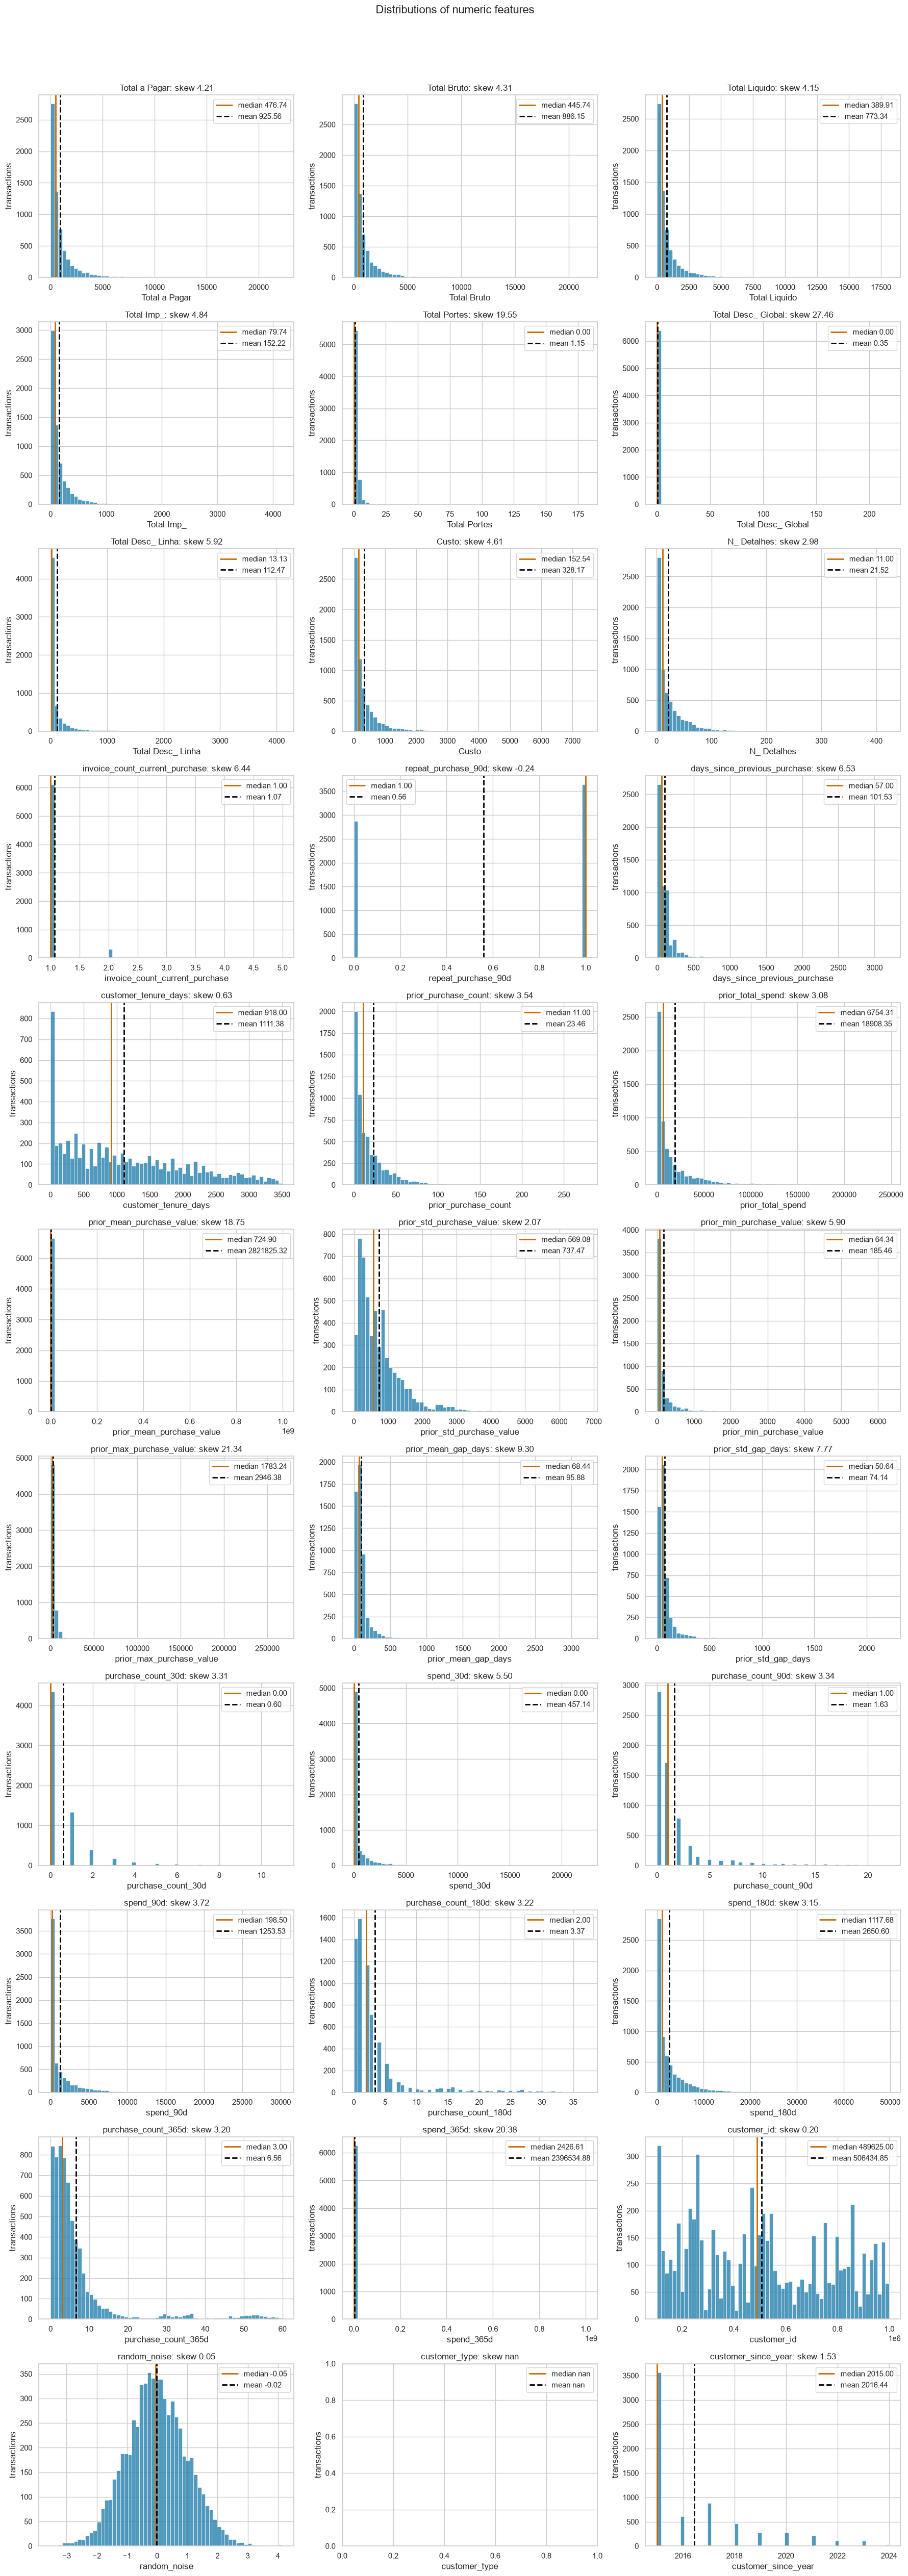

In [104]:

numeric_df = raw.select_dtypes(include=["number"])
columns_to_plot = numeric_df.columns.tolist()

# Number of columns in the grid
n_cols = 3
n_rows = math.ceil(len(columns_to_plot) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 4.5 * n_rows),
)

# Make axes iterable even when there is only one row
axes = np.atleast_1d(axes).ravel()

for ax, column in zip(axes, columns_to_plot):
    values = raw[column].dropna()

    sns.histplot(
        values,
        bins=60,
        color=PLOT_BLUE,
        ax=ax,
    )

    ax.axvline(
        values.median(),
        color=PLOT_ORANGE,
        lw=2,
        label=f"median {values.median():.2f}",
    )

    ax.axvline(
        values.mean(),
        color="black",
        lw=2,
        ls="--",
        label=f"mean {values.mean():.2f}",
    )

    ax.set(
        xlabel=column,
        ylabel="transactions",
        title=f"{column}: skew {values.skew():.2f}",
    )

    ax.legend()

# Hide unused subplots if the grid is not completely filled
for ax in axes[len(columns_to_plot):]:
    ax.set_visible(False)

fig.suptitle(
    "Distributions of numeric features",
    fontsize=16,
    y=1.02,
)

plt.tight_layout()
plt.show()

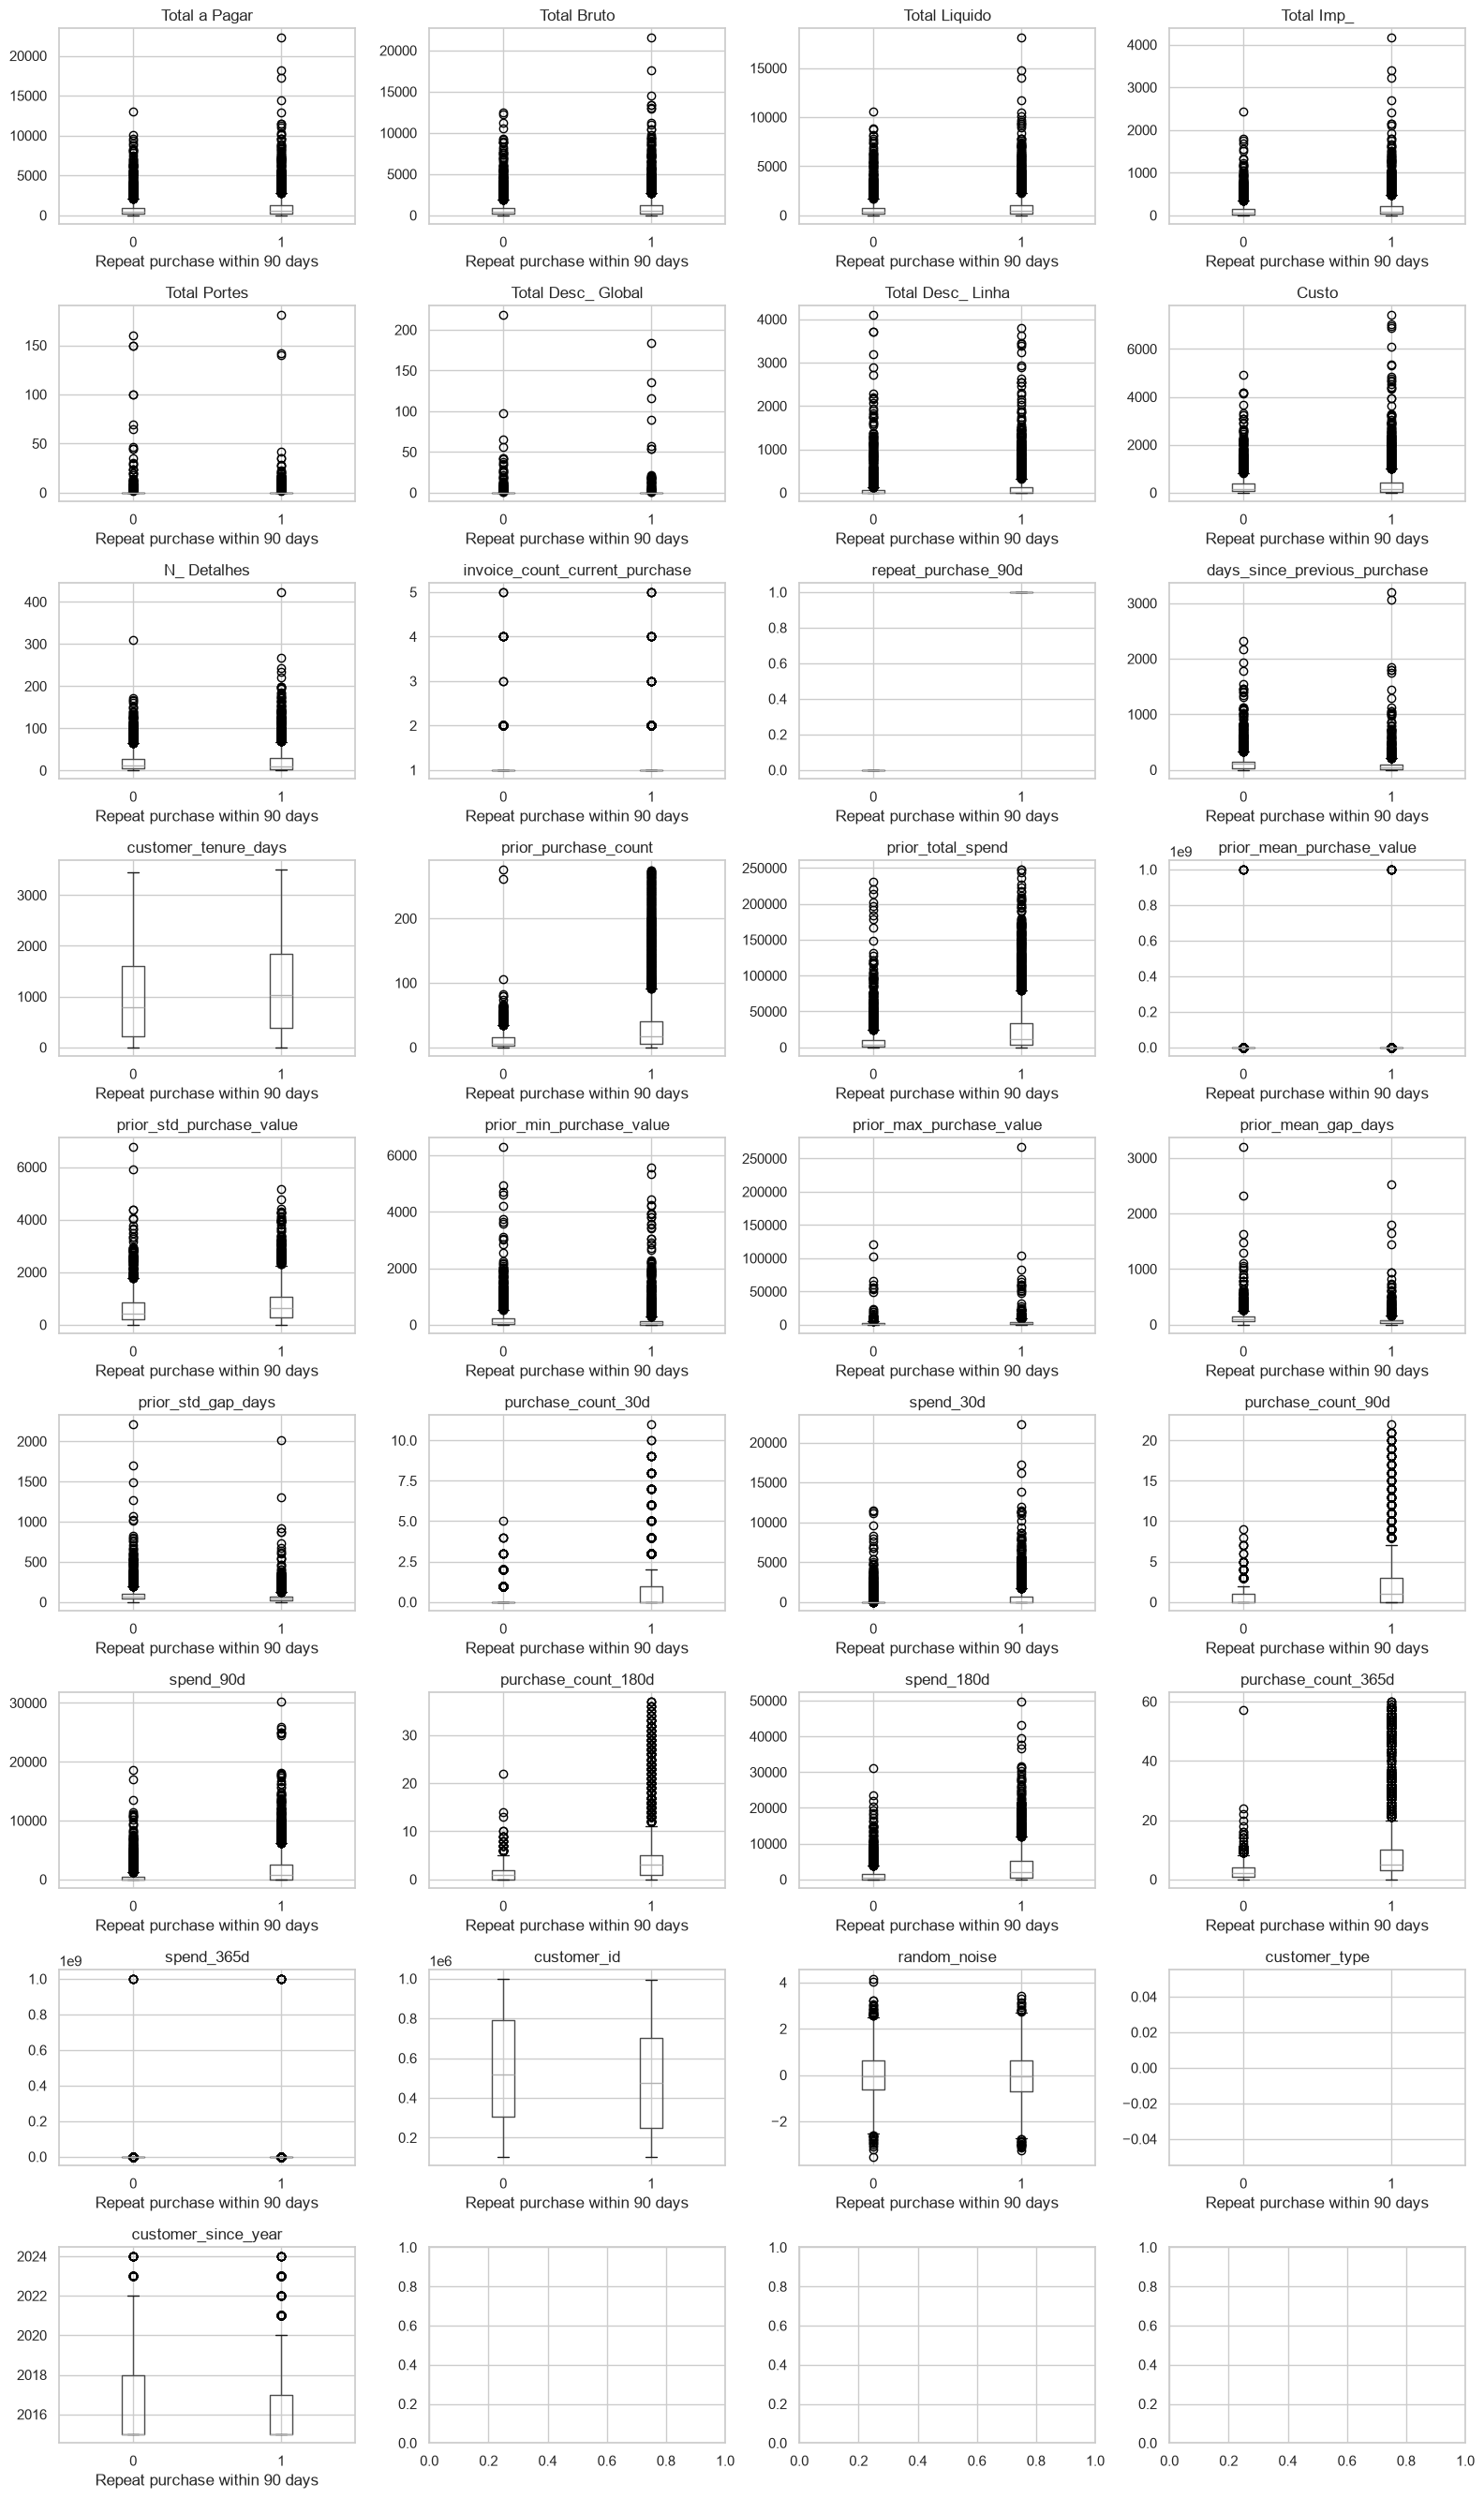

In [105]:
n_cols = 4
n_rows = (len(columns_to_plot) + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(16, n_rows * 3)
)

axes = axes.flatten()

for i, col in enumerate(columns_to_plot):
    raw.boxplot(
        column=col,
        by="repeat_purchase_90d",
        ax=axes[i]
    )
    axes[i].set_title(col)
    axes[i].set_xlabel("Repeat purchase within 90 days")
    axes[i].set_ylabel("")

plt.suptitle("")
plt.tight_layout()
plt.show()

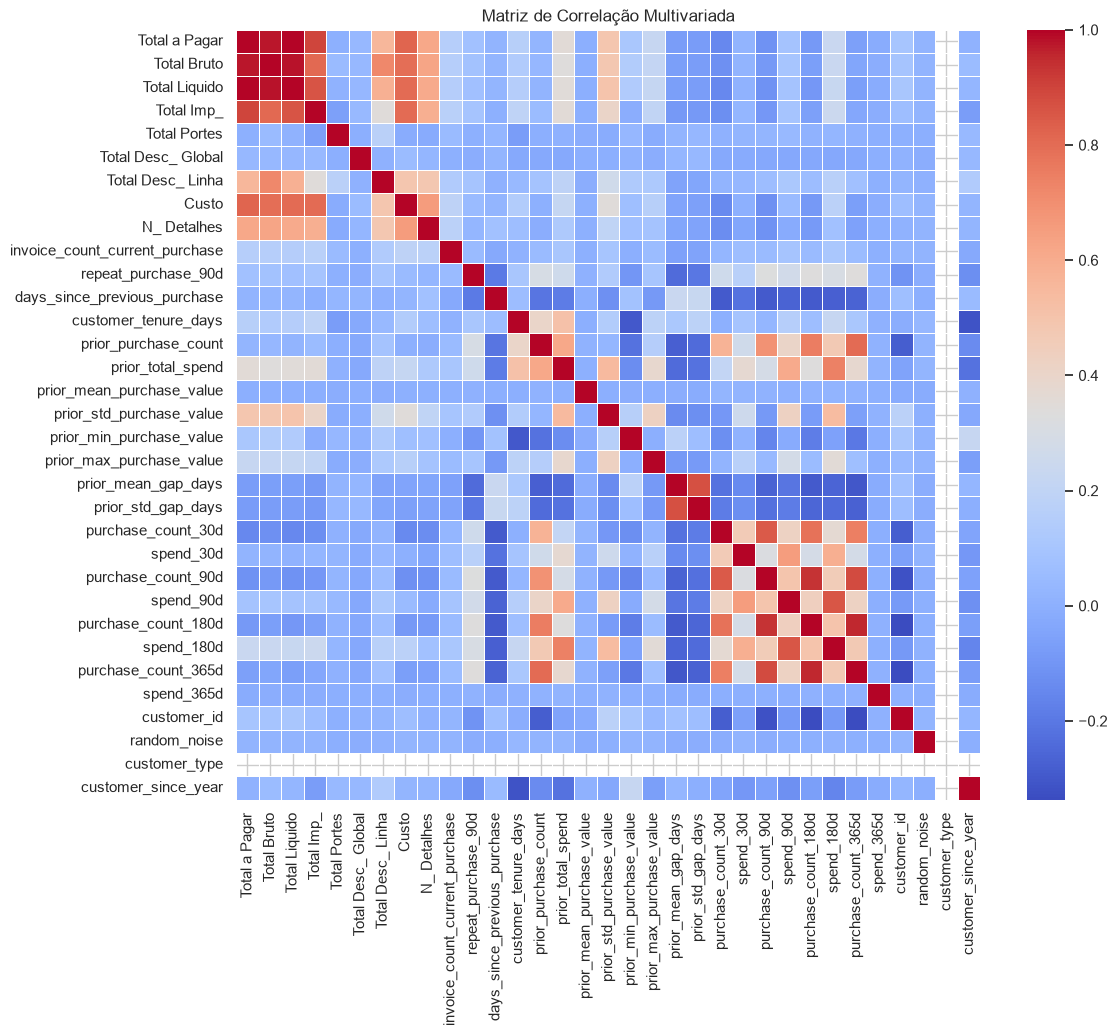

In [106]:
# Calcular a correlação
corr_matrix = numeric_df.corr()

# Desenhar o Heatmap (Mapa de Calor)
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', linewidths=0.5)
plt.title("Matriz de Correlação Multivariada")
plt.show()

# <font color='#E8800A'>An invalid value is not always missing data</font> <a class="anchor" id="invalid"></a>

In [107]:
# Select every numeric column except random_noise.
# customer_id and repeat_purchase_90d are already excluded from numeric.
non_negative = [
    column for column in numeric
    if column != "random_noise"
]

print("Numeric columns checked for negative values:")
print(non_negative)

print("\nNegative-value check:")
for column in non_negative:
    print(
        f"{column:32s} "
        f"min {raw[column].min():10.2f} "
        f"negative rows {(raw[column] < 0).sum():5d}"
    )

# Count rows and cells containing null values before cleaning.
rows_with_null_before = raw.isna().any(axis=1)
null_cells_before = raw.isna().sum().sum()

# Create a cleaned copy without changing raw.
step3 = raw.copy()

# Replace negative values with NaN in every selected numeric column.
step3[non_negative] = step3[non_negative].mask(
    step3[non_negative] < 0
)

# Count rows and cells containing null values after cleaning.
rows_with_null_after = step3.isna().any(axis=1)
null_cells_after = step3.isna().sum().sum()

print(
    f"\nrows with a null: {rows_with_null_before.sum():,} -> "
    f"{rows_with_null_after.sum():,} "
    f"({100 * rows_with_null_after.mean():.2f}% of {len(step3):,})"
)

print(
    f"null cells:       {null_cells_before:,} -> "
    f"{null_cells_after:,}"
)

Numeric columns checked for negative values:
['Total a Pagar', 'Total Bruto', 'Total Liquido', 'Total Imp_', 'Total Portes', 'Total Desc_ Global', 'Total Desc_ Linha', 'Custo', 'N_ Detalhes', 'invoice_count_current_purchase', 'days_since_previous_purchase', 'customer_tenure_days', 'prior_purchase_count', 'prior_total_spend', 'prior_mean_purchase_value', 'prior_std_purchase_value', 'prior_min_purchase_value', 'prior_max_purchase_value', 'prior_mean_gap_days', 'prior_std_gap_days', 'purchase_count_30d', 'spend_30d', 'purchase_count_90d', 'spend_90d', 'purchase_count_180d', 'spend_180d', 'purchase_count_365d', 'spend_365d', 'customer_since_year']

Negative-value check:
Total a Pagar                    min       0.93 negative rows     0
Total Bruto                      min       0.83 negative rows     0
Total Liquido                    min       0.76 negative rows     0
Total Imp_                       min       0.00 negative rows     0
Total Portes                     min       0.00 negat

In [108]:
non_negative = [
    column for column in numeric
    if column != "random_noise"
]

for column in non_negative:
    print(
        f"{column:32s} "
        f"min {raw[column].min():10.2f} "
        f"negative rows {(raw[column] < 0).sum():5d}"
    )

rows_with_null_before = raw.isna().any(axis=1)

step3 = raw.copy()
step3[non_negative] = step3[non_negative].mask(
    step3[non_negative] < 0
)

rows_with_null_after = step3.isna().any(axis=1)

print(
    f"\nrows with a null: {rows_with_null_before.sum():,} -> "
    f"{rows_with_null_after.sum():,} "
    f"({100 * rows_with_null_after.mean():.2f}% of {len(step3):,})"
)

print(
    f"null cells:       {raw.isna().sum().sum():,} -> "
    f"{step3.isna().sum().sum():,}"
)

Total a Pagar                    min       0.93 negative rows     0
Total Bruto                      min       0.83 negative rows     0
Total Liquido                    min       0.76 negative rows     0
Total Imp_                       min       0.00 negative rows     0
Total Portes                     min       0.00 negative rows     0
Total Desc_ Global               min       0.00 negative rows     0
Total Desc_ Linha                min       0.00 negative rows     0
Custo                            min       0.00 negative rows     0
N_ Detalhes                      min       1.00 negative rows     0
invoice_count_current_purchase   min       1.00 negative rows     0
days_since_previous_purchase     min      -4.00 negative rows    16
customer_tenure_days             min       0.00 negative rows     0
prior_purchase_count             min       0.00 negative rows     0
prior_total_spend                min       0.00 negative rows     0
prior_mean_purchase_value        min   -2478.66 

In [109]:
negative_days_since_previous_purchase = raw["days_since_previous_purchase"] < 0
raw.loc[negative_days_since_previous_purchase, "days_since_previous_purchase"].value_counts().to_frame(
    "rows at this value")

,rows at this value
days_since_previous_purchase,
-4.0,16


In [110]:
negative_prior_mean_purchase_value = raw["prior_mean_purchase_value"] < 0
raw.loc[negative_prior_mean_purchase_value, "prior_mean_purchase_value"].value_counts().to_frame(
    "rows at this value")

,rows at this value
prior_mean_purchase_value,
-110.147097,1
-409.791667,1
-218.266392,1
-417.917143,1
-779.030000,1
-212.360622,1
-366.120000,1
-2478.658478,1
-693.010000,1


In [111]:
negative_prior_mean_gap_days = raw["prior_mean_gap_days"] < 0
raw.loc[negative_prior_mean_gap_days, "prior_mean_gap_days"].value_counts().to_frame("rows at this value")

,rows at this value
prior_mean_gap_days,
-4.0,16


In [112]:
negative_spend_365d = raw["spend_365d"] < 0
raw.loc[negative_spend_365d, "spend_365d"].value_counts().to_frame("rows at this value")

,rows at this value
spend_365d,
-3456.320000,1
-1230.720000,1
-167.180000,1
-753.510000,1
-2648.440000,1
-2169.910000,1
-1443.640000,1
-5133.040000,1
-14740.290000,1


# <font color='#E8800A'>Noise feature</font> <a class="anchor" id="noise"></a>

In [113]:
raw.groupby("repeat_purchase_90d")["random_noise"].describe()

,count,mean,std,min,25%,50%,75%,max
repeat_purchase_90d,,,,,,,,
0,2848.0,-0.008609,0.996088,-3.529210,-0.642745,-0.043238,0.635513,4.151241
1,3621.0,-0.032783,1.004952,-3.263267,-0.715974,-0.047517,0.649046,3.435928


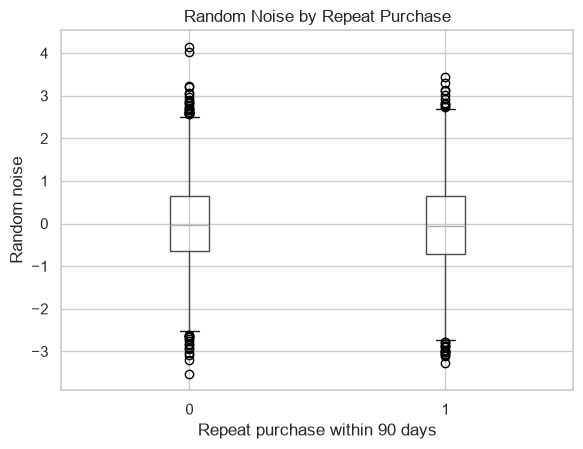

In [114]:
raw.boxplot(
    column="random_noise",
    by="repeat_purchase_90d"
)

plt.xlabel("Repeat purchase within 90 days")
plt.ylabel("Random noise")
plt.title("Random Noise by Repeat Purchase")
plt.suptitle("")
plt.show()

# <font color='#E8800A'>String features against the target</font> <a class="anchor" id="categorical_target"></a>

The chi-square test checks if a string column and the target are related, for example if some payment types come back more often than others.

- **p** below 0.05 means the relation is probably not luck.
- **Cramér's V** says how strong it is: 0 is no relation, 1 means the column decides the target.

One problem: the same customer appears in many rows (one has 277). If a customer buys often, everything about them (city, address...) looks related to the target. So the test is also run keeping only **one purchase per customer** (20 random picks, median p).

In [115]:
categorical_features = [
    column for column in raw.select_dtypes(include="str").columns
    if column != "purchase_date"
]


def chi_square(data, column):
    # Missing values count as their own category, and categories with fewer
    # than 30 rows are grouped into "Other" (the test is unreliable on tiny groups)
    values = data[column].fillna("Missing")
    values = values.where(values.map(values.value_counts()) >= 30, "Other")

    table = pd.crosstab(values, data[target])
    if len(table) < 2:
        return np.nan, np.nan
    return chi2_contingency(table).pvalue, association(table, method="cramer")


# One random purchase per customer, drawn 20 times, so each customer counts once
one_per_customer = [
    raw.groupby("customer_id").sample(1, random_state=seed) for seed in range(20)
]

rows = []
for column in categorical_features:
    p, cramers_v = chi_square(raw, column)
    rows.append({
        "feature": column,
        "categories": raw[column].nunique(),
        "p": p,
        "Cramer's V": cramers_v,
        "p, 1 purchase per customer": np.median(
            [chi_square(sample, column)[0] for sample in one_per_customer]
        ),
    })

pd.DataFrame(rows).set_index("feature").sort_values("Cramer's V", ascending=False).round(3)

,categories,p,Cramer's V,"p, 1 purchase per customer"
feature,,,,
company_name,609,0.000,0.485,NaN
address,600,0.000,0.484,NaN
postal_code,519,0.000,0.478,NaN
city,260,0.000,0.380,0.493
postal_area,189,0.000,0.354,0.643
municipality,150,0.000,0.333,0.719
street,266,0.000,0.297,0.704
commercial_region,32,0.000,0.261,0.679
transport_method,80,0.000,0.257,0.235


#### Conclusions

- **Location and company columns** (`company_name`, `address`, `postal_code`, `city`, `postal_area`, `municipality`, `street`, `commercial_region`, `island`, `country_or_region`) look related when using all rows, but not with one purchase per customer (p 0.5–0.7, or no result because every customer is a different category). They just identify the customer, so they are not useful on their own.
- **`payment_type` and `salesperson`** stay related with one purchase per customer (p 0.01 and 0.03). These are the most useful string columns.
- **`transport_method`** is in between (p 0.24 per customer). Worth trying in the model.
- **`commercial_zone`, `warehouse` and `document_series`** are barely related (V below 0.07).

This test looks at one column at a time, so it is a first filter: the final decision on the in-between columns should come from the model.